In [36]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from models.model2_mobs import Model2
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm

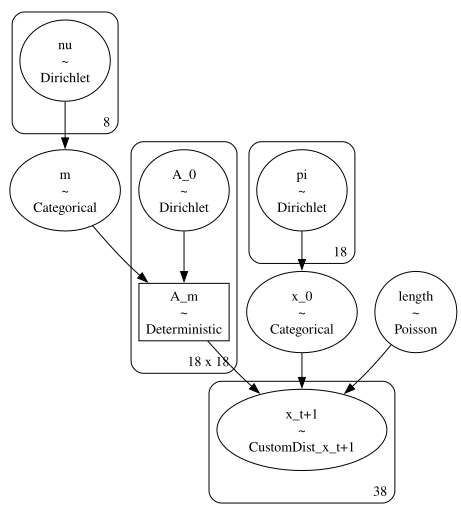

In [37]:
m2 = Model2()
m2.alpha = get_d2g_alpha(m2.V)

beta = TransitionPrior(m2.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
m2.beta = beta.get_beta()
m2.build_model()
pm.model_to_graphviz(m2.model)


In [4]:
#samples = m2.prior_predict(1)
#m2.show_melody(samples[0])

In [5]:
#samples

In [6]:
#import models.model_utils as u

#u.plot_heatmap(samples[0]["A_0"].sel(chain=0,draw=0).to_numpy())


In [7]:

#u.plot_heatmap(samples[0]["A_m"].sel(chain=0,draw=0).to_numpy())

In [21]:
import importlib
import analysis.compare_dist_of_intv as compare
import pandas as pd
importlib.reload(compare)

GS = pd.read_csv("data/data_gs.csv")
GS = GS[["volpiano_pitches", "modus"]].dropna()
data = GS[GS["modus"].isin(["1","2","3","4","5","6","7","8"])]
#data["modus"] = data["modus"].apply(lambda x: int(x)-1) # Index 0
data

,volpiano_pitches,modus
0,gghjhghhggkklhgfghhghkjkhkkkklhhghgkkhjggffhkj...,8
1,hhhghgeghghjhghghjhghkjkjkjhhjkjkjhjjhghjklkkj...,2
3,hgfghgegffedfghgfghgegfffehghgghhhghghgefgffdf...,4
4,cdddfddcddfgffffddefdcdacffefdddfddcddfgfffgff...,2
5,gjhhhhkhkkhgjghjhhhkhklmkjhhgjhgggfhghhfghkkhg...,2
...,...,...
154,kklkhhhggggjhhgggfghhghfffhghfhghghkkkkkgfgghg...,5
155,ddeddffffghfddfefefddddeddfefgdedccefffdgfghgg...,2
156,ggfffdeccdffghkhhgghfgkjjjjhgghghjkghffhkkkjkh...,8
157,dffgfffffghhfgfedgffgfffhfghkklmnkkhklkkkkhkhj...,5


In [22]:
data.modus.value_counts()

modus
2    22
1    22
8    21
5    20
4    14
6    13
3    11
7    11
Name: count, dtype: int64

In [23]:
raw_sequences = data["volpiano_pitches"].tolist()
    
raw_m = None
if "modus" in data.columns and data["modus"].notna().any():
    raw_m = data["modus"].astype(int).tolist()

trace = m2.fit_from_raw(
        raw_sequences=raw_sequences,
        raw_m=raw_m,
        draws=200,
        tune=100,
        backup="samples/model2_mobs_test.nc"
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [nu, A_0, pi]


Output()

Sampling 4 chains for 100 tune and 200 draw iterations (400 + 800 draws total) took 364 seconds.
There were 279 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


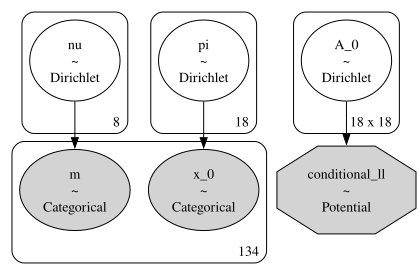

In [34]:
pm.model_to_graphviz(m2.model)

array([[<Axes: title={'center': 'nu'}>, <Axes: title={'center': 'nu'}>],
       [<Axes: title={'center': 'A_0'}>, <Axes: title={'center': 'A_0'}>],
       [<Axes: title={'center': 'pi'}>, <Axes: title={'center': 'pi'}>]],
      dtype=object)

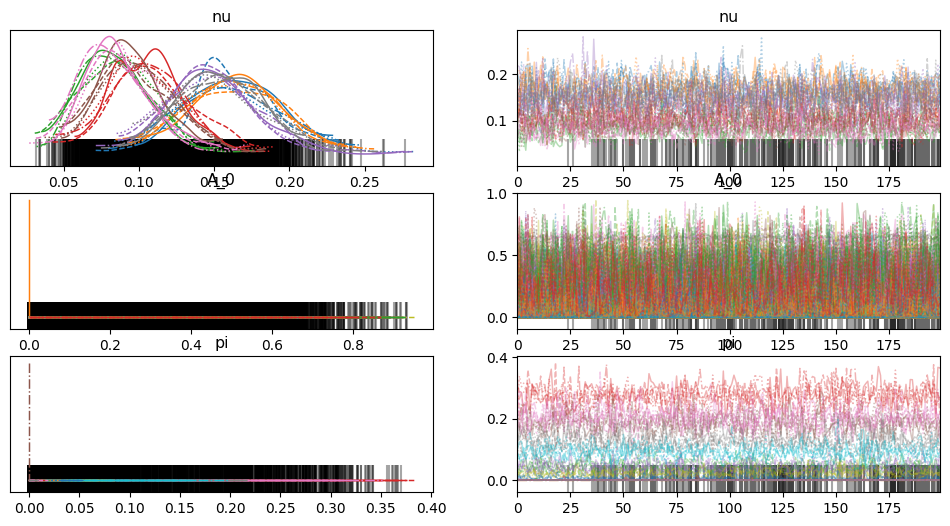

In [25]:
import arviz as az
az.plot_trace(trace, var_names=["nu", "A_0", "pi"])

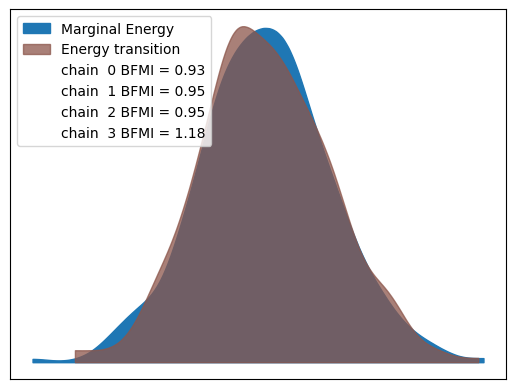

In [26]:
az.plot_energy(trace);

In [29]:
import seaborn as sns
def plot_posterior_matrix(trace, matrix_name="A_0"):


        posterior_mean = trace.posterior[matrix_name].mean(dim=["chain", "draw"]).values
        
        plt.figure(figsize=(10, 8))
        sns.heatmap(
            posterior_mean, 
            xticklabels=m2.alphabet, 
            yticklabels=m2.alphabet, 
            cmap="binary",
            annot=False
        )
        plt.title("Posterior Mean Transition Matrix")
        plt.xlabel("To Pitch")
        plt.ylabel("From Pitch")
        plt.show()

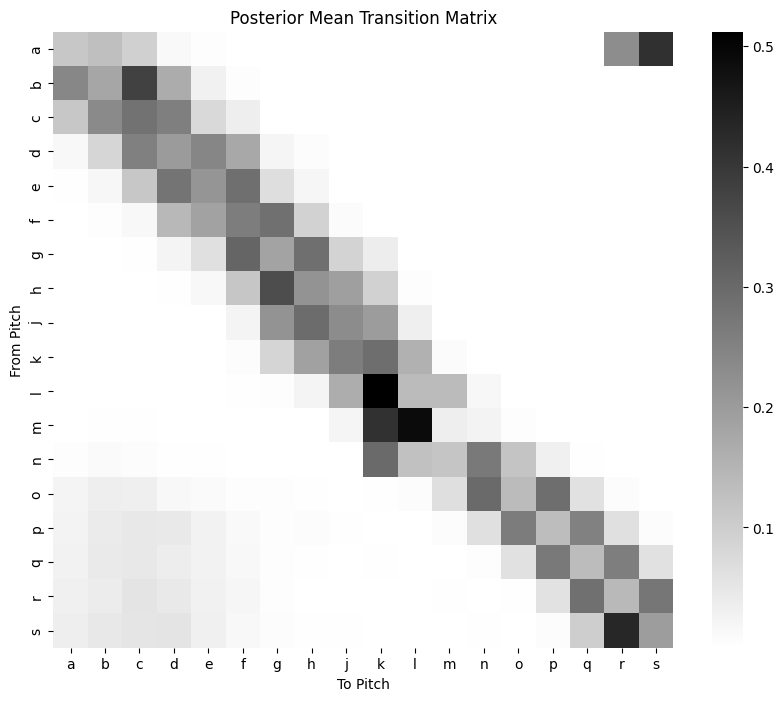

In [30]:
plot_posterior_matrix(m2.trace)

In [31]:
import analysis.visualise_posterior as vp

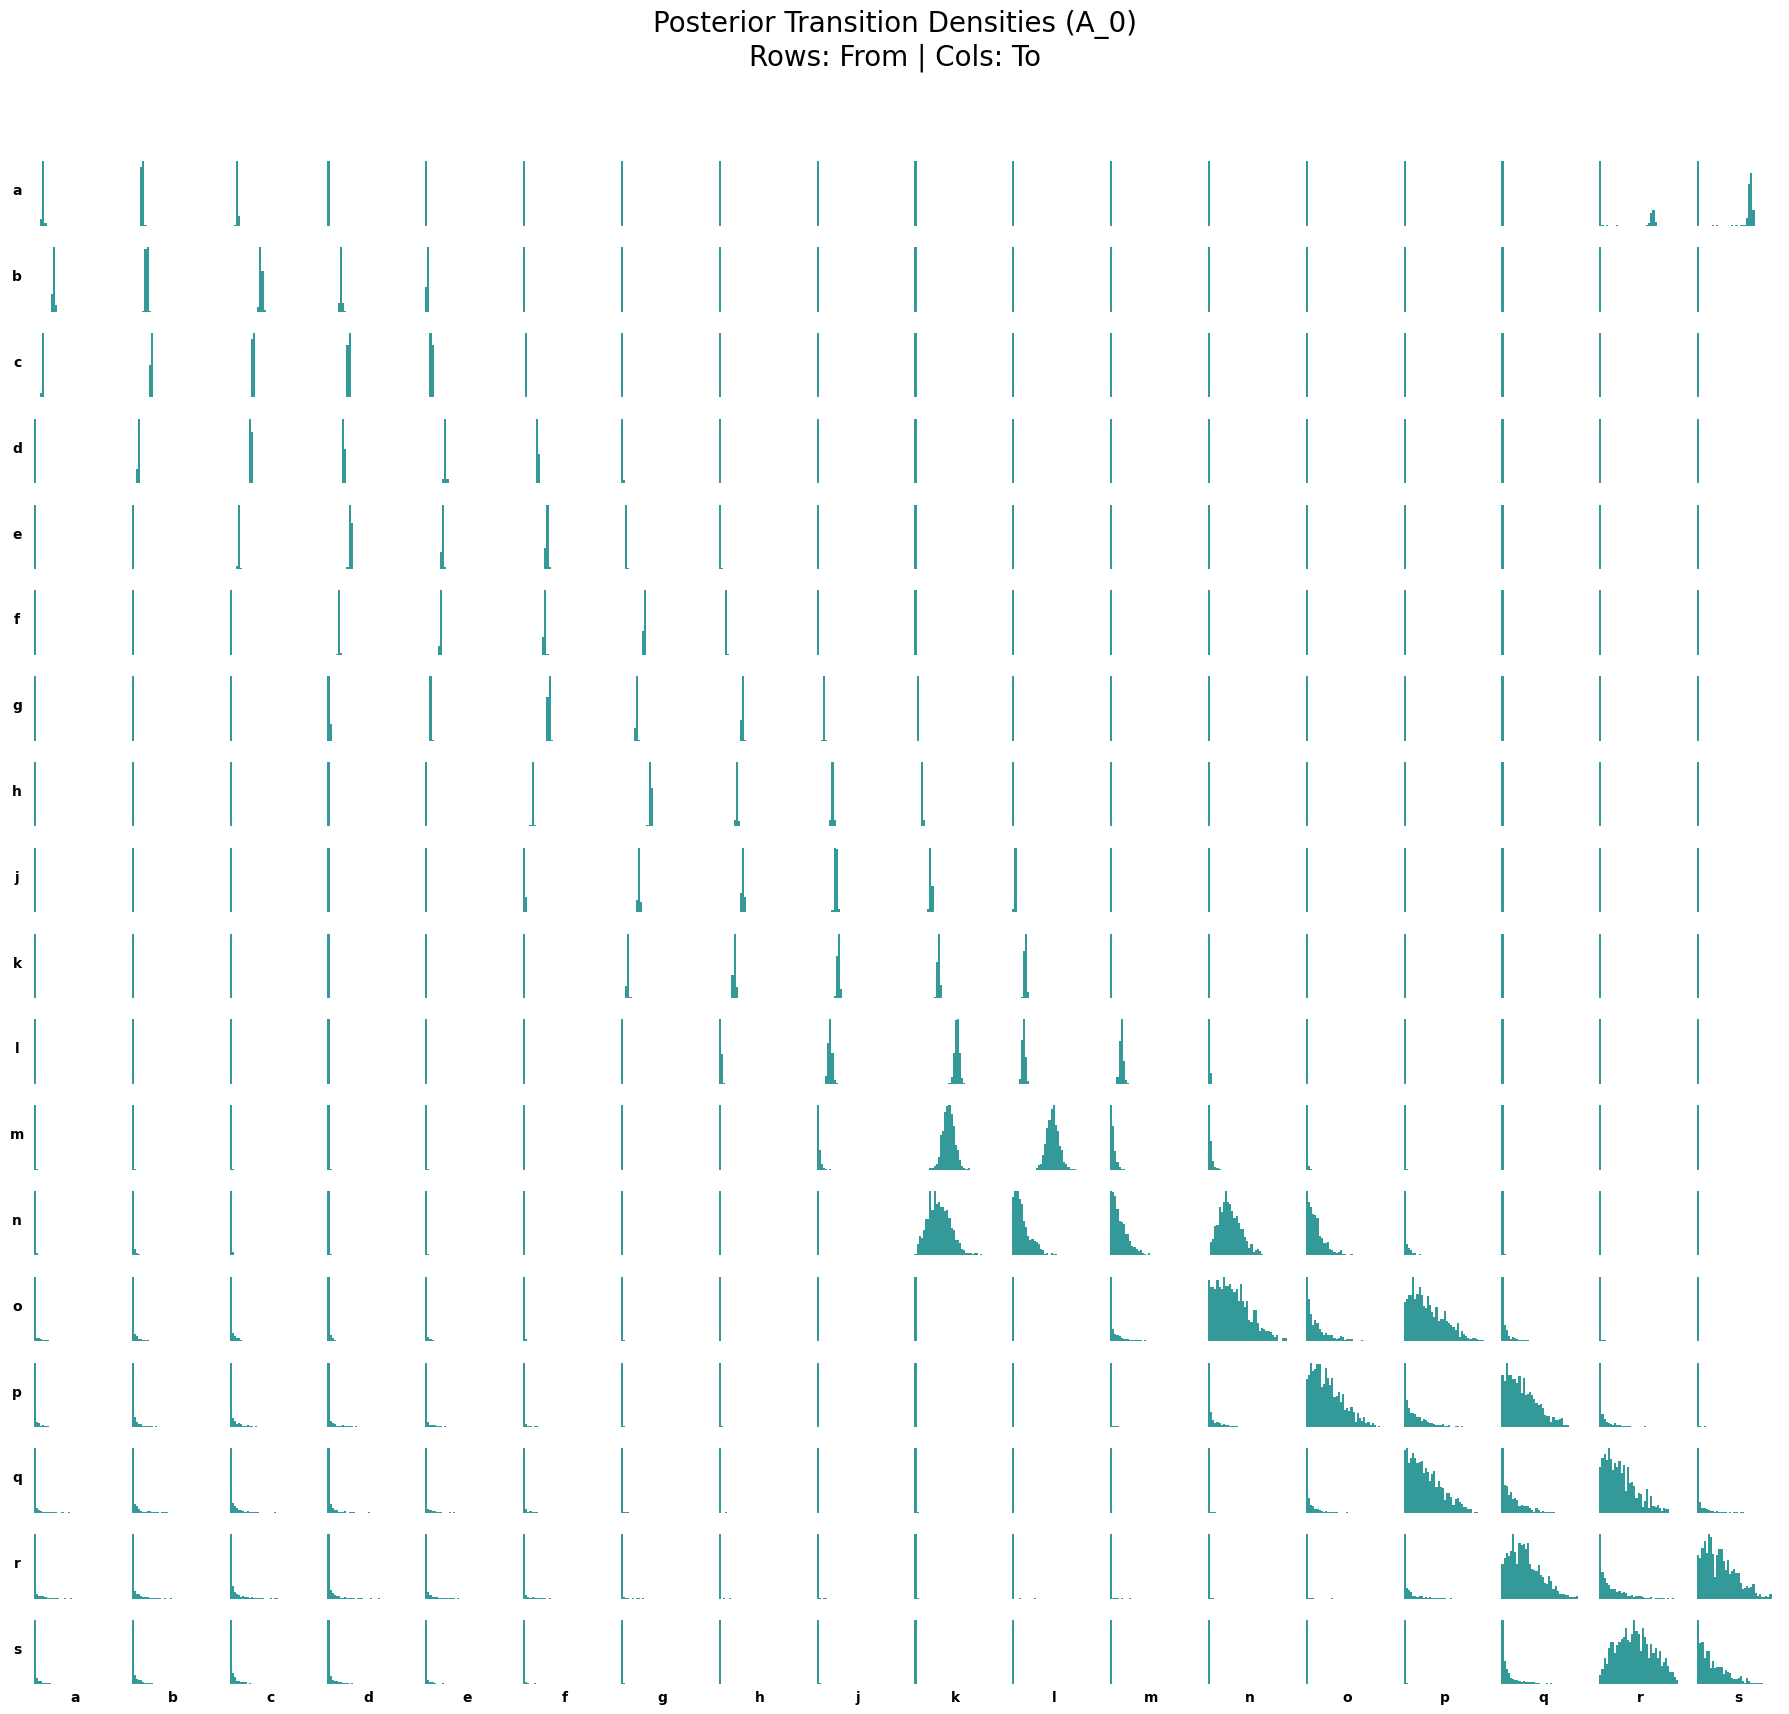

In [32]:
vp.plot_transition_matrix_posterior(m2.trace, "A_0")